# Patient Diagnosis Classification

Multi-class classification of patient diagnosis (depression, chronic illness, or both) from clinical and lifestyle features.
Team project, MSc Data Science and AI, University of Liverpool.

Place the dataset at `data/dataset_prepared.csv` before running.

In [ ]:
import warnings
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

sns.set_theme(style='whitegrid')
np.random.seed(42)
warnings.filterwarnings('ignore')


## 1. Data management

Exploratory analysis, feature cleaning, and a stratified 80/20 split with 5-fold cross-validation for tuning.

Dataset shape: (670, 19)

Data types:
id                                int64
age                               int64
gender                           object
country                          object
sleep_quality_index             float64
deep_sleep_quality_index        float64
brain_fog_level                 float64
physical_pain_score             float64
stress_level                    float64
depression_phq9_score             int64
fatigue_severity_scale_score    float64
pem_duration_hours                int64
hours_of_sleep_per_night        float64
pem_present                       int64
work_status                      object
social_activity_level            object
exercise_frequency               object
meditation_or_mindfulness        object
diagnosis                        object
dtype: object

First 5 rows:
 id  age gender country  sleep_quality_index  deep_sleep_quality_index  brain_fog_level  physical_pain_score  stress_level  depression_phq9_score  fatigue_severity_scale_sco

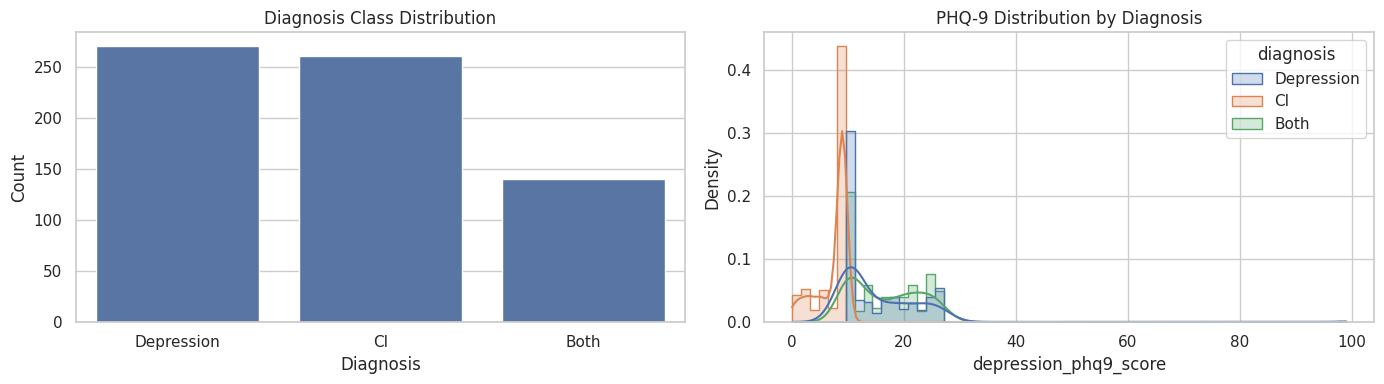

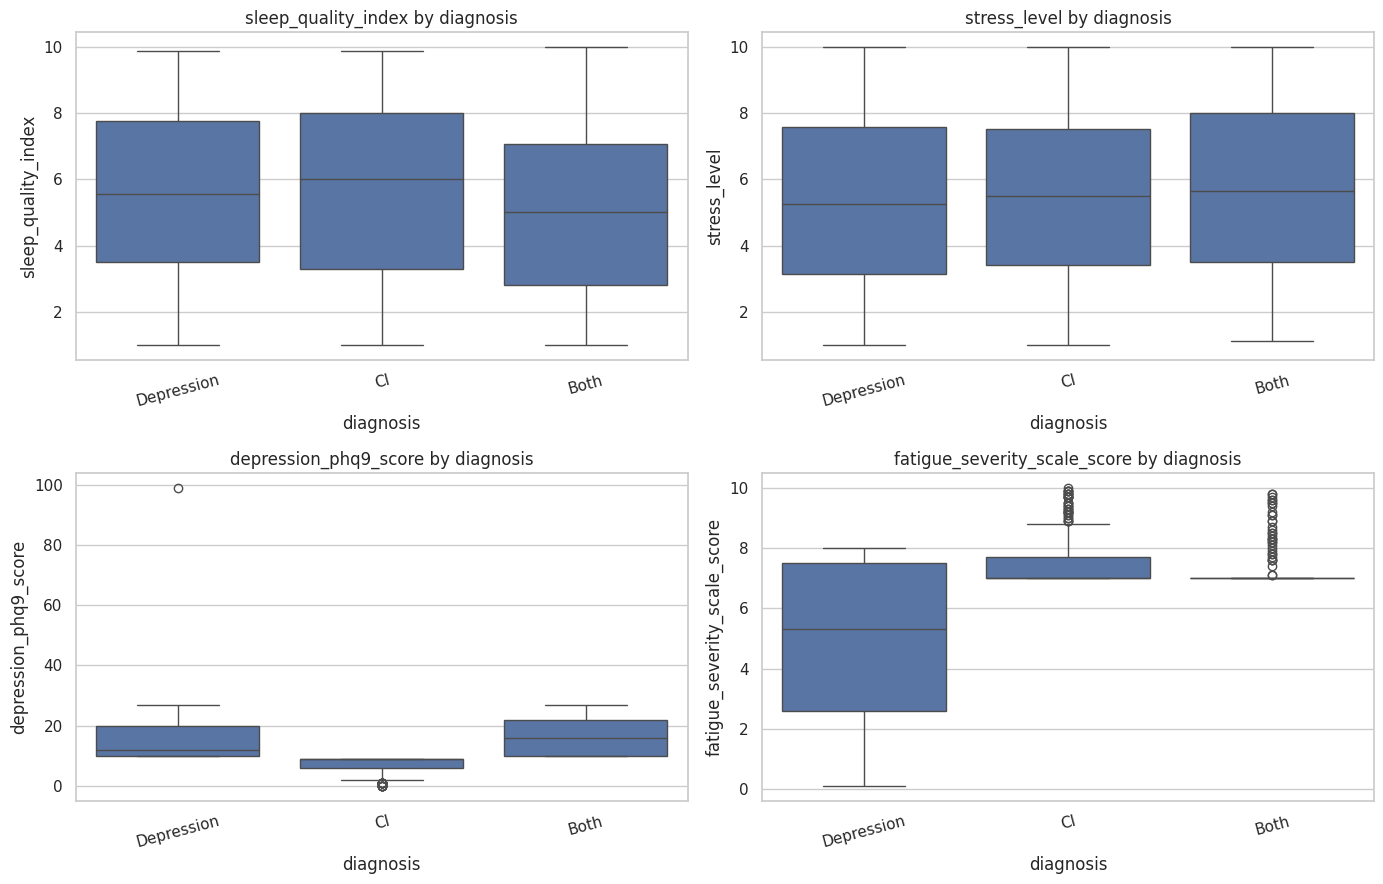

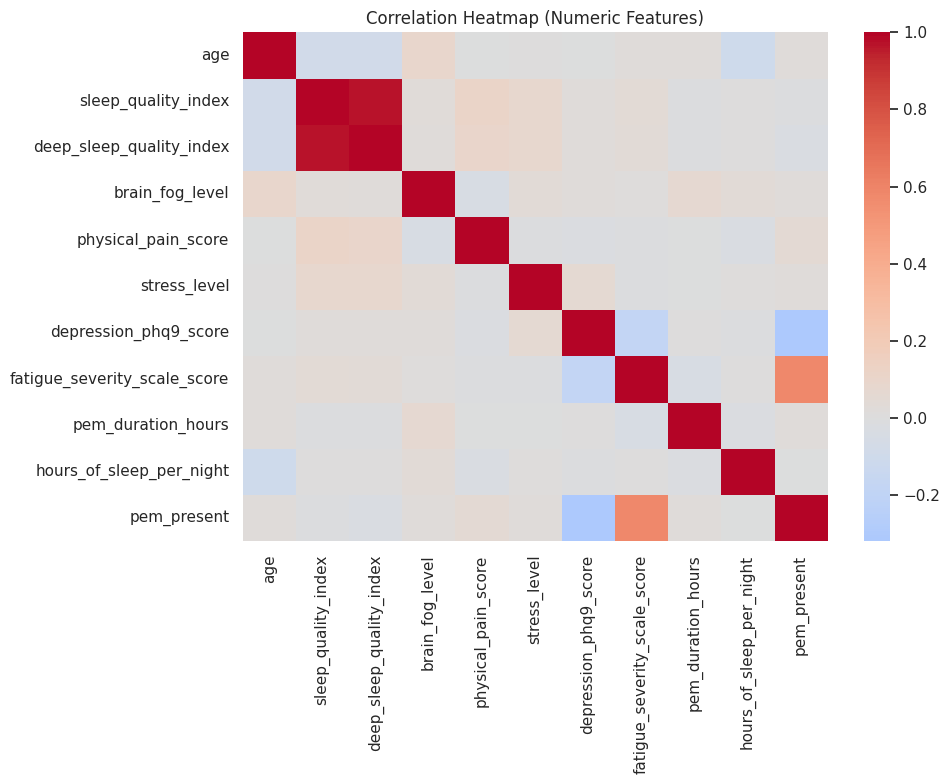


Categorical features: ['gender', 'work_status', 'social_activity_level', 'exercise_frequency', 'meditation_or_mindfulness']
Numeric features: ['age', 'sleep_quality_index', 'deep_sleep_quality_index', 'brain_fog_level', 'physical_pain_score', 'stress_level', 'depression_phq9_score', 'fatigue_severity_scale_score', 'pem_duration_hours', 'hours_of_sleep_per_night', 'pem_present']

Train set shape: (536, 16), Test set shape: (134, 16)

Train class distribution (%):
diagnosis
Depression    40.30
CI            38.81
Both          20.90
Name: proportion, dtype: float64

Test class distribution (%):
diagnosis
Depression    40.30
CI            38.81
Both          20.90
Name: proportion, dtype: float64


In [12]:

df = pd.read_csv("data/dataset_prepared.csv")
# Load dataset
print(f'Dataset shape: {df.shape}')
print()
print('Data types:')
print(df.dtypes)
print()
print('First 5 rows:')
print(df.head().to_string(index=False))

# Check data quality
print()
print('Missing values per column:')
print(df.isna().sum().sort_values(ascending=False))
print()
print('Target distribution:')
print(df['diagnosis'].value_counts())

# Identify potential low-information columns
constant_cols = [c for c in df.columns if df[c].nunique() <= 1]
unique_id_cols = [c for c in df.columns if df[c].nunique() == len(df)]
print()
print('Constant columns:', constant_cols)
print('Unique-ID-like columns:', unique_id_cols)

# Drop obvious non-predictive fields: patient id + any constant columns
drop_cols = sorted(set(['id'] + constant_cols))
drop_cols = [c for c in drop_cols if c in df.columns]
df_model = df.drop(columns=drop_cols).copy()
print()
print('Dropped columns:', drop_cols)
print('Data shape after dropping columns:', df_model.shape)

# Quick exploratory plots
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=df_model, x='diagnosis', order=df_model['diagnosis'].value_counts().index, ax=axes[0])
axes[0].set_title('Diagnosis Class Distribution')
axes[0].set_xlabel('Diagnosis')
axes[0].set_ylabel('Count')

sns.histplot(
    data=df_model,
    x='depression_phq9_score',
    hue='diagnosis',
    kde=True,
    stat='density',
    common_norm=False,
    element='step',
    ax=axes[1],
)
axes[1].set_title('PHQ-9 Distribution by Diagnosis')
plt.tight_layout()
plt.show()

selected_features = [
    'sleep_quality_index',
    'stress_level',
    'depression_phq9_score',
    'fatigue_severity_scale_score',
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for i, feature in enumerate(selected_features):
    ax = axes[i // 2, i % 2]
    sns.boxplot(data=df_model, x='diagnosis', y=feature, ax=ax)
    ax.set_title(f'{feature} by diagnosis')
    ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

numeric_corr = df_model.select_dtypes(include=np.number).corr()
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_corr, cmap='coolwarm', center=0)
plt.title('Correlation Heatmap (Numeric Features)')
plt.tight_layout()
plt.show()

# Define features and labels
X = df_model.drop(columns=['diagnosis'])
y = df_model['diagnosis']

categorical_features = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
print()
print('Categorical features:', categorical_features)
print('Numeric features:', numeric_features)

# Preprocessing pipeline: impute + scale numeric, impute + one-hot encode categorical
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore')),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features),
    ]
)

# Experimental protocol: stratified train/test split + stratified 5-fold CV for tuning
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

cv_protocol = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print()
print(f'Train set shape: {X_train.shape}, Test set shape: {X_test.shape}')
print()
print('Train class distribution (%):')
print((y_train.value_counts(normalize=True) * 100).round(2))
print()
print('Test class distribution (%):')
print((y_test.value_counts(normalize=True) * 100).round(2))


## 2. Model training

Logistic regression, RBF SVM, random forest and k-NN compared inside one preprocessing pipeline, tuned with GridSearchCV on balanced accuracy.

In [ ]:

# Define candidate models and hyperparameter grids
model_search_space = [
    (
        'Logistic Regression',
        LogisticRegression(max_iter=5000, random_state=42),
        {
            'model__C': [0.1, 0.5, 1.0, 3.0, 10.0],
            'model__solver': ['lbfgs'],
        },
    ),
    (
        'SVM (RBF)',
        SVC(random_state=42),
        {
            'model__kernel': ['rbf'],
            'model__C': [0.5, 1.0, 3.0, 10.0],
            'model__gamma': ['scale', 0.1, 0.01],
        },
    ),
    (
        'Random Forest',
        RandomForestClassifier(random_state=42),
        {
            'model__n_estimators': [200, 400],
            'model__max_depth': [None, 8, 14],
            'model__min_samples_leaf': [1, 2, 4],
            'model__class_weight': [None, 'balanced'],
        },
    ),
    (
        'kNN',
        KNeighborsClassifier(),
        {
            'model__n_neighbors': [3, 5, 7, 11, 15],
            'model__weights': ['uniform', 'distance'],
        },
    ),
]

trained_searches = {}
summary_rows = []
top_trials_by_model = {}

for model_name, estimator, param_grid in model_search_space:
    print(f'\nRunning grid search for: {model_name}')

    pipeline = Pipeline(
        steps=[
            ('preprocess', preprocessor),
            ('model', estimator),
        ]
    )

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring='balanced_accuracy',
        cv=cv_protocol,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
    )

    search.fit(X_train, y_train)
    trained_searches[model_name] = search

    summary_rows.append(
        {
            'model': model_name,
            'best_cv_balanced_accuracy': search.best_score_,
            'best_params': search.best_params_,
        }
    )

    cv_df = pd.DataFrame(search.cv_results_).sort_values('rank_test_score')
    top_trials_by_model[model_name] = cv_df[
        ['mean_test_score', 'std_test_score', 'mean_train_score', 'params']
    ].head(5)

results_df = pd.DataFrame(summary_rows).sort_values(
    'best_cv_balanced_accuracy',
    ascending=False,
).reset_index(drop=True)

print('\nBest CV result per model:')
print(results_df[['model', 'best_cv_balanced_accuracy']].to_string(index=False))

print('\nTop hyperparameter trials per model (by CV balanced accuracy):')
for model_name, table in top_trials_by_model.items():
    print(f'\n{model_name}')
    print(table.to_string(index=False))

best_model_name = results_df.loc[0, 'model']
best_model = trained_searches[best_model_name].best_estimator_
best_model_cv_score = results_df.loc[0, 'best_cv_balanced_accuracy']

print(f'\nSelected best model based on CV: {best_model_name}')
print(f'Best cross-validation balanced accuracy: {best_model_cv_score:.4f}')
print('Best hyperparameters:', trained_searches[best_model_name].best_params_)



Running grid search for: Logistic Regression

Running grid search for: SVM (RBF)

Running grid search for: Random Forest

Running grid search for: kNN

Best CV result per model:
              model  best_cv_balanced_accuracy
      Random Forest                   1.000000
Logistic Regression                   0.946665
          SVM (RBF)                   0.869302
                kNN                   0.814026

Top hyperparameter trials per model (by CV balanced accuracy):

Logistic Regression
 mean_test_score  std_test_score  mean_train_score                                       params
        0.946665        0.025722          0.988090 {'model__C': 10.0, 'model__solver': 'lbfgs'}
        0.921230        0.016932          0.960131  {'model__C': 3.0, 'model__solver': 'lbfgs'}
        0.883899        0.030268          0.922253  {'model__C': 1.0, 'model__solver': 'lbfgs'}
        0.883899        0.030268          0.905899  {'model__C': 0.5, 'model__solver': 'lbfgs'}
        0.864985     

## 3. Evaluation

The best model from tuning is evaluated once on the held-out test set.

Best model from tuning: Random Forest

Test-set metrics:
           metric  score
         Accuracy    1.0
Balanced Accuracy    1.0
  Macro Precision    1.0
     Macro Recall    1.0
         Macro F1    1.0

Detailed classification report:
              precision    recall  f1-score   support

        Both       1.00      1.00      1.00        28
          CI       1.00      1.00      1.00        52
  Depression       1.00      1.00      1.00        54

    accuracy                           1.00       134
   macro avg       1.00      1.00      1.00       134
weighted avg       1.00      1.00      1.00       134



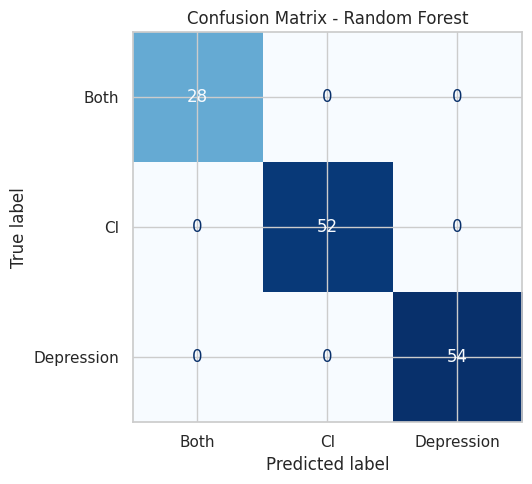

In [ ]:

# Evaluate the best model on the held-out test set
y_pred = best_model.predict(X_test)

test_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred),
    'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
    'Macro Precision': precision_score(y_test, y_pred, average='macro'),
    'Macro Recall': recall_score(y_test, y_pred, average='macro'),
    'Macro F1': f1_score(y_test, y_pred, average='macro'),
}

metrics_df = pd.DataFrame({'metric': list(test_metrics.keys()), 'score': list(test_metrics.values())})
print(f'Best model from tuning: {best_model_name}')
print('\nTest-set metrics:')
print(metrics_df.to_string(index=False))

print('\nDetailed classification report:')
print(classification_report(y_test, y_pred))

# Visual representation - confusion matrix
label_order = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=label_order)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_order)
disp.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title(f'Confusion Matrix - {best_model_name}')
plt.tight_layout()
plt.show()
